# HealthRAG — Etapa 2: procesamiento documental y chunking

Extracción con PyMuPDF por página, eliminación de encabezados/pies repetidos, unión de líneas cortadas, detección de secciones (TOC del PDF + tipografía), tablas como filas indivisibles y chunks de ~200 tokens con 60 de solapamiento **sin mezclar páginas**.

In [1]:
import os, sys
from pathlib import Path

# Raíz del proyecto: funciona abriendo el notebook desde notebooks/ o desde la raíz.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from app.config import load_config, resolve_path
from app.utils.logging_config import configure_logging

cfg = load_config()
logger = configure_logging(cfg)
print("Proyecto:", ROOT)

Proyecto: HealthRAG


In [2]:
from app.ingestion.pdf_processor import process_corpus, read_chunks

p = cfg['processing']
stats = process_corpus(
    catalog_csv=resolve_path(cfg['corpus']['catalog_path']),
    output_jsonl=resolve_path(cfg['corpus']['chunks_path']),
    chunk_size=p['chunk_size_tokens'], overlap=p['chunk_overlap_tokens'],
    tokenizer_name=p['tokenizer_name'],
    header_footer_min_ratio=p['header_footer_min_ratio'],
    min_chunk_chars=p['min_chunk_chars'],
    exclude_sections=p.get('exclude_sections'),
)
display(stats)

2026-11-15 12:30:06,502 | INFO | healthrag.ingestion.tokenizer | Tokenizer cargado: intfloat/multilingual-e5-small


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (660 > 512). Running this sequence through the model will result in indexing errors


2026-11-15 12:30:37,694 | INFO | healthrag.ingestion.processor | Directriz_OMS_HTA: 277 chunks (11 grupos excluidos por sección)


2026-11-15 12:30:56,669 | INFO | healthrag.ingestion.processor | GPCN_HTA: 144 chunks (1 grupos excluidos por sección)


2026-11-15 12:31:34,233 | INFO | healthrag.ingestion.processor | GPCN_IAM: 380 chunks (9 grupos excluidos por sección)


2026-11-15 12:32:43,338 | INFO | healthrag.ingestion.processor | GPCN_prev_cardiovascular: 603 chunks (16 grupos excluidos por sección)


2026-11-15 12:33:00,065 | INFO | healthrag.ingestion.processor | Guia_OMS_prev_ECV: 110 chunks (1 grupos excluidos por sección)


2026-11-15 12:33:00,332 | INFO | healthrag.ingestion.processor | Total chunks: 1514 -> HealthRAG\data\processed\chunks.jsonl


,doc_id,chunks,pages,tokens_mean,tokens_min,tokens_max,sin_seccion
0,Directriz_OMS_HTA,277,53,136.3,13,216,0
1,GPCN_HTA,144,39,125.2,8,201,0
2,GPCN_IAM,380,71,145.3,11,200,0
3,GPCN_prev_cardiovascular,603,136,147.9,9,232,0
4,Guia_OMS_prev_ECV,110,35,121.4,31,200,0


Tokenizer usado: intfloat/multilingual-e5-small


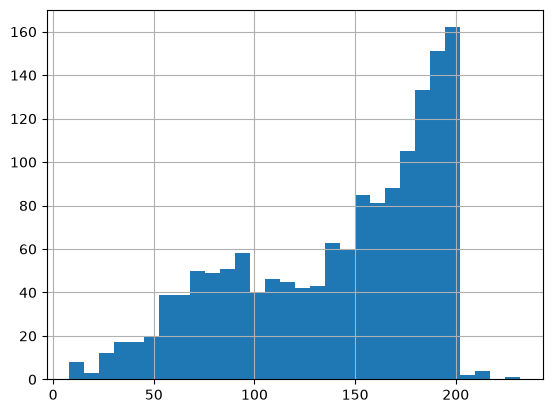

In [3]:
import pandas as pd
from dataclasses import asdict
chunks = read_chunks(resolve_path(cfg['corpus']['chunks_path']))
df = pd.DataFrame([asdict(c) for c in chunks])
print('Tokenizer usado:', df['metadata'].iloc[0]['tokenizer'])
df['n_tokens'].hist(bins=30);

## Validación manual
Revisar una muestra: que no se corten tablas, valores de presión arterial, dosis ni recomendaciones, y que sección/página coincidan con el PDF.

In [4]:
pd.set_option('display.max_colwidth', 300)
display(df.sample(min(10, len(df)), random_state=1)[['chunk_id', 'section', 'page', 'n_tokens', 'text']])

,chunk_id,section,page,n_tokens,text
572,GPCN_IAM_p35_c151,Resumen de evidencia - ATCp vs. Fibrinolíticos,35,194,"En estos estudios la diferencia temporal fue mínima (llegando inclusive a 7 y 10 minutos en dos ECA) lo cual resulta opuesto a lo que sucede en la realidad. Analizando pormenorizadamente este punto se observa que, de los 22 estudios incluidos en el MA, en 7 de ellos la diferencia entre ambos tra..."
984,GPCN_prev_cardiovascular_p47_c183,ERC) ¿Cuál es la dosis de estatinas efectiva para reducir el colesterol y,47,171,"Costos: Dado que las píldoras combinadas presentan un costo similar al de estatinas en monodroga, el panel consideró que el costo no suele ser una limitante. Implementabilidad: el panel consideró que, en prevención secundaria, el beneficio de adicionar ezetimibe al tratamiento con estatinas de m..."
1013,GPCN_prev_cardiovascular_p53_c212,En el cuestionario se valoraron para los últimos dos años:,53,182,2. Si ha firmado contrato con alguna organización que pueda verse afectada financieramente a partir de las recomendaciones de la GPC; si posee acciones o bonos de alguna organización o entidad comercial que pueda verse afectada financieramente a partir de las recomendaciones de la GPC. 3. Si pos...
536,GPCN_IAM_p28_c115,Tratamiento Fibrinolítico,28,176,El beneficio de esta terapia es máximo dentro de la primera hora de iniciado el cuadro (NNT=25) y persiste hasta las 12 hs. observándose una progresiva disminución de su efectividad sobre la mortalidad total con la demora en la administración (NNT=45 para su administración entre las 7 y las 12 h...
1145,GPCN_prev_cardiovascular_p109_c344,"En personas con ECV establecida, los tratamientos con estatinas de alta intensidad",109,169,"En personas con ECV establecida, los tratamientos con estatinas de alta intensidad reducen un 15% más los ECVM, en comparación con tratamientos con estatinas de moderada intensidad. En los 5 ECA para intensidad de tratamiento (droga cabeza cabeza: alta intensidad: 2 ECA atorvastatina 80 mg, 2 EC..."
309,GPCN_HTA_p12_c32,3. Metas del tratamiento,12,182,"- Se considera hipotensión ortostática a un descenso sostenido mayor a 20 mmHg en la presión arterial sistóli ca y/o 10 mmHg en la presión arterial diastólica dentro de los 3 primeros minutos de la bipedestación. A medida que aumenta la edad, el desarrollo de “rigidez arterial” conlleva un aumen..."
1369,GPCN_prev_cardiovascular_p156_c568,ANEXO 7. REVISIÓN EXTERNA,156,170,habitualmente introducimos en nuestras guías: Nota valoración de la evidencia: respecto a la valoración global de la evidencia si bien la metodología GRADE propone realizar la valoración global acorde a la menor calidad de evidencia alcanzada entre los desenlaces críticos para una determinada in...
248,Directriz_OMS_HTA_p58_c248,Importancia de los resultados para la toma de decisiones,58,53,"Importancia de los resultados para la toma de decisiones 8,6 Accidente cerebrovascular 8,4 Infarto de miocardio 8,1 Cardiopatía coronaria 8,0 Muerte por ECV 7,9 Insuficiencia cardíaca 7,8 IRT"
181,Directriz_OMS_HTA_p36_c181,4.3 Embarazo e hipertensión,36,141,"4.3 Embarazo e hipertensión La hipertensión, incluidas la HTA crónica, la HTA gestacional, la preeclampsia y la eclampsia, es una afección médica muy común en el embarazo (99). Debido a las consecuencias adversas de su elevada morbilidad y mortalidad tanto para las mujeres como para el feto, la ..."
91,Directriz_OMS_HTA_p23_c91,Datos y argumentos justificativos,23,180,"Además, esta evidencia no debe sugerir que las personas con riesgo intermedio no obtengan un beneficio importante con el tratamiento. No hubo datos probatorios de los efectos indeseables previstos de iniciar el tratamiento basado en la estratificación del riesgo cardiovascular. Sin embargo, la d..."


In [5]:
# Buscar fragmentos con valores clínicos para verificar que estén completos
display(df[df['text'].str.contains(r'mmHg|mg/d|g/d', regex=True)][['chunk_id', 'page', 'text']].head(15))

,chunk_id,page,text
20,Directriz_OMS_HTA_p9_c20,9,1. RECOMENDACIONES SOBRE EL UMBRAL DE TENSIÓN ARTERIAL PARA EL INICIO DEL TRATAMIENTO FARMACOLÓGICO La OMS recomienda el inicio del tratamiento farmacológico antihipertensivo para las personas con un diagnóstico confirmado de hipertensión y tensión arterial sistólica ≥140 mmHg o tensión arterial...
21,Directriz_OMS_HTA_p9_c21,9,"RESUMEN EJECUTIVO Recomendación sólida, certidumbre de la evidencia de moderada a alta La OMS recomienda el tratamiento farmacológico antihipertensivo para las personas con enfermedades cardiovasculares existentes y tensión arterial sistólica de 130-139 mmHg. Recomendación sólida, certidumbre de..."
22,Directriz_OMS_HTA_p10_c22,10,"La OMS sugiere el tratamiento farmacológico antihipertensivo para las personas sin enfermedades cardiovasculares, pero con riesgo cardiovascular alto, diabetes mellitus o insuficiencia renal crónica y tensión arterial sistólica de 130-139 mmHg. Recomendación condicional, certidumbre de la eviden..."
27,Directriz_OMS_HTA_p10_c27,10,"6. RECOMENDACIONES SOBRE EL OBJETIVO DE TENSIÓN ARTERIAL La OMS recomienda un objetivo de tratamiento para la tensión arterial <140/90 mmHg para los pacientes hipertensos sin comorbilidades. Recomendación sólida, certidumbre de la evidencia moderada viii"
28,Directriz_OMS_HTA_p11_c28,11,"La OMS recomienda un objetivo de tratamiento para la tensión arterial sistólica <130 mmHg en los pacientes hipertensos con enfermedades cardiovasculares (ECV) conocidas. Recomendación sólida, certidumbre de la evidencia moderada La OMS sugiere un objetivo de tratamiento para la tensión arterial ..."
66,Directriz_OMS_HTA_p19_c66,19,3 Recomendaciones 3.1 Umbral de tensión arterial para el inicio del tratamiento farmacológico 1. RECOMENDACIONES SOBRE EL UMBRAL DE TENSIÓN ARTERIAL PARA EL INICIO DEL TRATAMIENTO FARMACOLÓGICO La OMS recomienda el inicio del tratamiento farmacológico antihipertensivo para las personas con un di...
67,Directriz_OMS_HTA_p19_c67,19,"Recomendación sólida, certidumbre de la evidencia de moderada a alta La OMS recomienda el tratamiento farmacológico antihipertensivo para las personas con enfermedades cardiovasculares existentes y tensión arterial sistólica de 130-139 mmHg. Recomendación sólida, certidumbre de la evidencia de m..."
68,Directriz_OMS_HTA_p19_c68,19,"Recomendación condicional, certidumbre de la evidencia de moderada a alta Observaciones de aplicación: El tratamiento farmacológico de la hipertensión debe iniciarse, a más tardar, cuatro semanas - después de su diagnóstico. Si el valor de tensión arterial es alto (p. ej., sistólica ≥160 mmHg o..."
69,Directriz_OMS_HTA_p19_c69,19,Datos y argumentos justificativos El GED analizó la evidencia de 14 revisiones sistemáticas pertinentes que resumían los datos de un gran número de ensayos aleatorios con más de 120 000 participantes adultos (anexo A del sitio web). Los resúmenes de la evidencia se presentan para la población ge...
74,Directriz_OMS_HTA_p20_c74,20,"La mayoría de las estimaciones de rentabilidad se agruparon por debajo de US$ 1000 por año de vida ajustado por discapacidad (AVAD), muy por debajo del promedio del PIB per cápita de 2017 para los países de ingresos medianos bajos, que fue de US$ 2188 (17), lo que sugiere que el tratamiento farm..."
